# Лабораторная работа № 3
## Теория катастроф в IT-системах

**Тема:** катастрофа «сборка» в модели веб-сервиса с балансировщиком нагрузки.

**Цель:** построить бифуркационное множество, численно воспроизвести скачки
состояния при росте и снижении нагрузки и подтвердить гистерезис.

Источник задания: «ЛР 3(теория катастроф) (1).pdf», стр. 1–2.
В задании нет таблицы вариантов; параметры выбраны и обоснованы ниже.
Все расчёты детерминированы, внешние данные и файлы не требуются.

Для повторения: Python 3.11+, `pip install -r requirements-lab3.txt`, затем
**Restart Kernel and Run All Cells**. Рисунки и таблицы сохранены в выходах ячеек.

## 1. Математическая модель
### 1.1. Согласование формул задания

На стр. 1 записано $V_0=x^4-ux^2+v$. Буквально
$-\partial V_0/\partial x=-4x^3+2ux$: параметр $v$ исчезает, поэтому его изменение
не вызывает ни скачка, ни петли гистерезиса. На стр. 2 дано другое уравнение:

$$\dot x=-(4x^3-2ux+v).$$

Именно оно используется в расчёте. Ему соответствует исправленный потенциал

$$V(x,u,v)=x^4-ux^2+vx,\qquad \dot x=-\frac{\partial V}{\partial x}.$$

При фиксированных $u,v$ выполняется
$dV/dt=-(\partial V/\partial x)^2\leq0$: система стремится к локальному минимуму.
При меняющемся $v$ добавляется член $x\dot v$, поэтому убывание потенциала во
время прохода нагрузки не предполагается.

### 1.2. Смысл переменных и ограничения

В данной нормальной форме $x$ — **знаковая безразмерная координата состояния**.
Рост $v$ сдвигает устойчивое состояние к меньшим $x$, поэтому непосредственно
называть $x$ положительным временем отклика некорректно. Для интерпретации введём
условные положительные величины

$$\tau=3-x,\qquad \lambda=5+v.$$

Тогда $\tau$ — показатель времени отклика, $\lambda$ — показатель входящего
трафика; они измеряются в условных единицах. Знак преобразования обеспечивает
рост времени отклика при росте нагрузки. Сдвиги 3 и 5 выбраны для наглядности
на исследуемом диапазоне и не являются калибровкой в миллисекунды или запросы/с.

$u$ — эффективный коэффициент масштабирования. Без связи с измерениями он не
тождественен физическому числу серверов; вывод о пользе добавления инстансов
из одного изменения $u$ не делается. Модель иллюстрирует механизм переключения,
но не подтверждает наличие катастрофы в конкретном реальном сервисе.

### 1.3. Библиотеки и параметры

In [1]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "figure.dpi": 120, "savefig.dpi": 180,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GRAY = "#2864a0", "#c35b20", "#62666c"
U = 3.0
V_MIN, V_MAX = -4.0, 4.0
RATE = 0.005
TAU_OFFSET, LOAD_OFFSET = 3.0, 5.0
RTOL, ATOL, MAX_STEP = 1e-8, 1e-10, 0.5

def potential(x, u, v):
    return x**4 - u*x**2 + v*x

def gradient(x, u, v):
    return 4*x**3 - 2*u*x + v

def equilibria(u, v):
    roots = np.roots([4.0, 0.0, -2*u, v])
    return np.sort(roots.real[np.abs(roots.imag) < 1e-8])

def fold_limit(u):
    return np.sqrt(8*u**3/27) if u > 0 else 0.0

V_CRIT = fold_limit(U)
X_FOLD = np.sqrt(U/6)
duration = (V_MAX - V_MIN)/RATE
display(pd.DataFrame({
    "Параметр": ["u", "Диапазон v", "Скорость |dv/dt|", "Время одного прохода",
                 "Метод", "rtol / atol", "Максимальный шаг"],
    "Значение": [U, f"[{V_MIN}; {V_MAX}]", RATE, duration,
                 "DOP853", f"{RTOL} / {ATOL}", MAX_STEP],
}))
print(f"Python {sys.version.split()[0]}; NumPy {np.__version__}; "
      f"SciPy {scipy.__version__}; Matplotlib {matplotlib.__version__}")

,Параметр,Значение
0,u,3.0
1,Диапазон v,[-4.0; 4.0]
2,Скорость |dv/dt|,0.005
3,Время одного прохода,1600.0
4,Метод,DOP853
5,rtol / atol,1e-08 / 1e-10
6,Максимальный шаг,0.5


Python 3.11.5; NumPy 2.3.5; SciPy 1.17.1; Matplotlib 3.10.7


## 2. Равновесия, устойчивость и бифуркации

Стационарные состояния удовлетворяют $4x^3-2ux+v=0$.
Для малого возмущения $\delta x$ имеем
$\delta\dot x=(2u-12x_*^2)\delta x$.
Минимум устойчив, если $12x_*^2-2u>0$; максимум неустойчив при обратном знаке.

На складках одновременно выполняются

$$4x^3-2ux+v=0,\qquad 12x^2-2u=0.$$

Отсюда $u=6x^2$, $v=8x^3$, следовательно,

$$\boxed{8u^3=27v^2},\qquad
v_\pm=\pm\sqrt{\frac{8u^3}{27}}.$$

При $u>0$ и $8u^3>27v^2$ существуют три различных равновесия:
два устойчивых и одно неустойчивое. Снаружи — одно устойчивое равновесие.
На гладкой части границы устойчивое и неустойчивое состояния сливаются;
в начале координат находится вершина сборки.

Для $u=3$ получаем $x_\pm=\pm\sqrt{1/2}$ и
$v_\pm=\pm2\sqrt2\approx\pm2{,}828427$.
Диапазон $[-4;4]$ пересекает обе складки, поэтому позволяет наблюдать полный цикл.

In [2]:
rows = []
for x_eq in equilibria(U, 0.0):
    curvature = 12*x_eq**2 - 2*U
    rows.append([x_eq, curvature, -curvature,
                 "Устойчиво" if curvature > 0 else "Неустойчиво"])
equilibrium_table = pd.DataFrame(rows, columns=[
    "x* при v=0", "V''(x*)", "f'(x*)", "Устойчивость"])
display(equilibrium_table.round(6))
scaling_table = pd.DataFrame({"u": [0, 1, 2, 3, 4]})
scaling_table["v критическое"] = [fold_limit(u) for u in scaling_table["u"]]
scaling_table["Ширина статической петли"] = 2*scaling_table["v критическое"]
display(scaling_table.round(6))

,x* при v=0,V''(x*),f'(x*),Устойчивость
0,-1.224745,12.0,-12.0,Устойчиво
1,0.000000,-6.0,6.0,Неустойчиво
2,1.224745,12.0,-12.0,Устойчиво


,u,v критическое,Ширина статической петли
0,0,0.000000,0.000000
1,1,0.544331,1.088662
2,2,1.539601,3.079201
3,3,2.828427,5.656854
4,4,4.354648,8.709297


### 2.1. Изменение формы потенциала

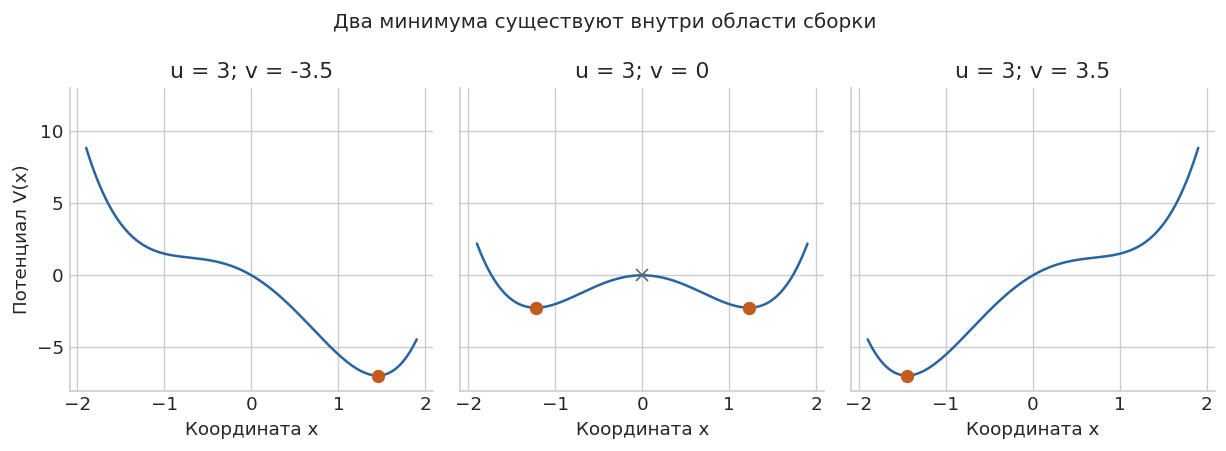

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharey=True)
x_grid = np.linspace(-1.9, 1.9, 1000)
for ax, v in zip(axes, [-3.5, 0.0, 3.5]):
    ax.plot(x_grid, potential(x_grid, U, v), color=BLUE)
    for x_eq in equilibria(U, v):
        stable = 12*x_eq**2 - 2*U > 0
        ax.plot(x_eq, potential(x_eq, U, v), "o" if stable else "x",
                color=ORANGE if stable else GRAY, markersize=7)
    ax.set(title=f"u = 3; v = {v:g}", xlabel="Координата x", ylim=(-8, 13))
axes[0].set_ylabel("Потенциал V(x)")
fig.suptitle("Два минимума существуют внутри области сборки", fontsize=12)
fig.tight_layout()
plt.show()

Кружки обозначают устойчивые минимумы, крестик — неустойчивый максимум. При v=0 обе потенциальные ямы имеют одинаковую глубину. При достаточно большом по модулю v одна из ям исчезает.

### 2.2. Бифуркационное множество

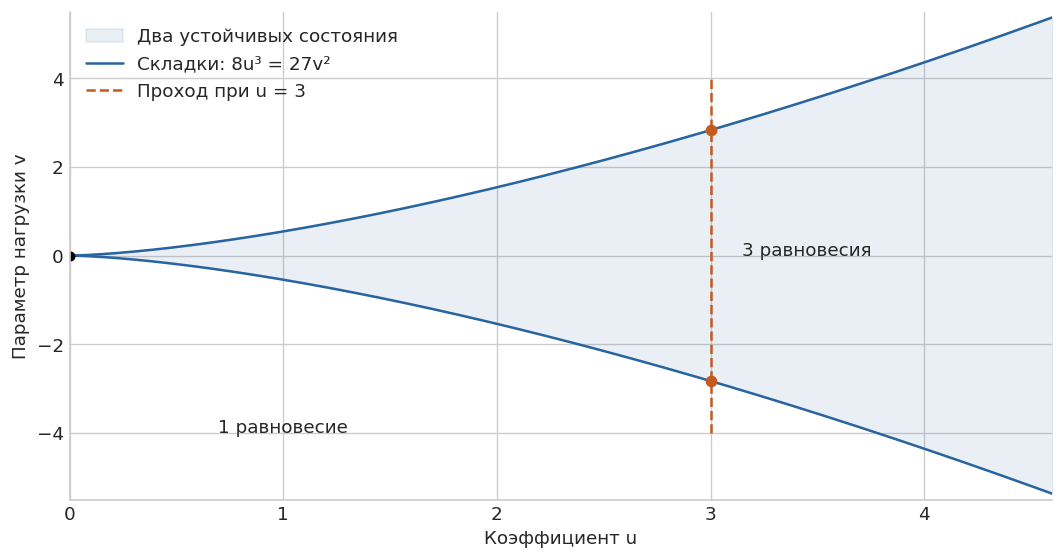

In [4]:
u_grid = np.linspace(0, 4.6, 600)
v_boundary = np.sqrt(8*u_grid**3/27)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.fill_between(u_grid, -v_boundary, v_boundary, color=BLUE, alpha=0.10,
                label="Два устойчивых состояния")
ax.plot(u_grid, v_boundary, color=BLUE, label="Складки: 8u³ = 27v²")
ax.plot(u_grid, -v_boundary, color=BLUE)
ax.plot([U, U], [V_MIN, V_MAX], "--", color=ORANGE, label="Проход при u = 3")
ax.scatter([U, U], [-V_CRIT, V_CRIT], color=ORANGE, zorder=5)
ax.plot(0, 0, "ko", markersize=5)
ax.text(3.45, 0, "3 равновесия", ha="center")
ax.text(1.0, -4, "1 равновесие", ha="center")
ax.set(xlabel="Коэффициент u", ylabel="Параметр нагрузки v", xlim=(0, 4.6), ylim=(-5.5, 5.5))
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## 3. Численный эксперимент

### 3.1. Прямой и обратный проход

В эксперименте A параметр линейно растёт:
$v_A(t)=-4+rt$, $0\le t\le T$, где $r=0{,}005$ и $T=1600$.
Начальное состояние — единственный устойчивый корень при $v=-4$.

В эксперименте B параметр убывает: $v_B(s)=4-rs$, $0\le s\le T$.
Принципиально важно: $x_B(0)=x_A(T)$, начальное состояние не выбирается заново.
Для совместного временного графика используется $t=T+s$.

Точка статической катастрофы — исчезновение минимума при $v=v_+$ или $v=v_-$.
В нестационарном расчёте переключение занимает конечное время. Для однозначного
измерения динамического порога используется событие **x=0** внутри скачка.
Это операционное определение; такой порог не следует отождествлять с самой складкой.

In [5]:
def simulate_cycle(rate=RATE, rtol=RTOL, atol=ATOL, max_step=MAX_STEP):
    span = (V_MAX - V_MIN)/rate
    initial = equilibria(U, V_MIN)[-1]

    def crossing(t, state):
        return state[0]

    def run(v_start, slope, x_initial):
        def rhs(t, state):
            return [-gradient(state[0], U, v_start + slope*t)]

        sol = solve_ivp(rhs, (0, span), [x_initial], method="DOP853",
                        rtol=rtol, atol=atol, max_step=max_step,
                        dense_output=True, events=crossing)
        if not sol.success or len(sol.t_events[0]) != 1:
            raise RuntimeError("Не удалось получить один переход: " + sol.message)
        return sol

    forward = run(V_MIN, rate, initial)
    reverse = run(V_MAX, -rate, forward.y[0, -1])
    forward_event = float(forward.t_events[0][0])
    reverse_event = float(reverse.t_events[0][0])
    return {
        "forward": forward, "reverse": reverse, "duration": span,
        "v_forward": V_MIN + rate*forward_event,
        "v_reverse": V_MAX - rate*reverse_event,
        "t_forward": forward_event, "t_reverse": span + reverse_event,
    }

cycle = simulate_cycle()
sol_forward, sol_reverse = cycle["forward"], cycle["reverse"]
sample_t = np.linspace(0, duration, 16001)
v_forward = V_MIN + RATE*sample_t
v_reverse = V_MAX - RATE*sample_t
x_forward = sol_forward.sol(sample_t)[0]
x_reverse = sol_reverse.sol(sample_t)[0]
tau_forward, tau_reverse = TAU_OFFSET-x_forward, TAU_OFFSET-x_reverse
transition_table = pd.DataFrame({
    "Проход": ["A: рост", "B: снижение"],
    "Статическая складка v": [V_CRIT, -V_CRIT],
    "Событие x=0, v": [cycle["v_forward"], cycle["v_reverse"]],
    "Глобальное время события": [cycle["t_forward"], cycle["t_reverse"]],
    "Отклонение по модулю": [cycle["v_forward"]-V_CRIT,
                            -V_CRIT-cycle["v_reverse"]],
})
display(transition_table.round(6))

,Проход,Статическая складка v,"Событие x=0, v",Глобальное время события,Отклонение по модулю
0,A: рост,2.828427,2.861717,1372.343467,0.03329
1,B: снижение,-2.828427,-2.861717,2972.343467,0.03329


### 3.2. Петля гистерезиса x(v)

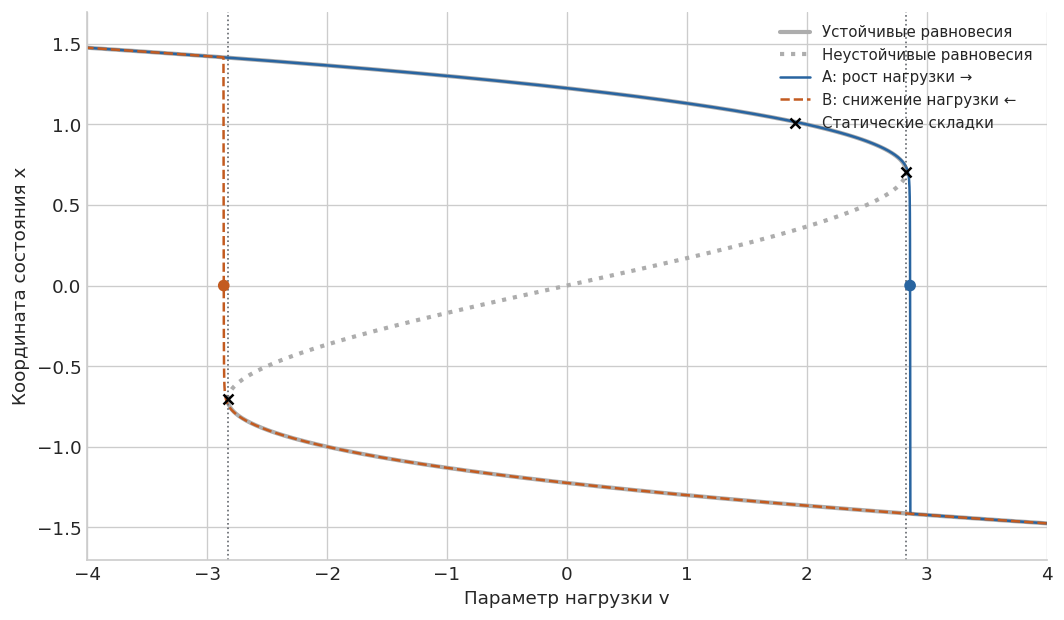

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.3))
branch_x = np.linspace(-1.7, 1.7, 3000)
branch_v = 2*U*branch_x - 4*branch_x**3
stable = np.abs(branch_x) > X_FOLD
for mask, style, label in [(stable, "-", "Устойчивые равновесия"),
                           (~stable, ":", "Неустойчивые равновесия")]:
    ax.plot(branch_v, np.where(mask, branch_x, np.nan), style,
            color="0.68", linewidth=2.5, label=label)
ax.plot(v_forward, x_forward, color=BLUE, label="A: рост нагрузки →")
ax.plot(v_reverse, x_reverse, "--", color=ORANGE, label="B: снижение нагрузки ←")
for v in [-V_CRIT, V_CRIT]:
    ax.axvline(v, color=GRAY, linestyle=":", linewidth=1)
ax.scatter([V_CRIT, -V_CRIT], [X_FOLD, -X_FOLD], color="black", marker="x",
           zorder=6, label="Статические складки")
ax.scatter([cycle["v_forward"], cycle["v_reverse"]], [0, 0],
           color=[BLUE, ORANGE], zorder=6)
ax.set(xlabel="Параметр нагрузки v", ylabel="Координата состояния x",
       xlim=(V_MIN, V_MAX), ylim=(-1.7, 1.7))
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

In [7]:
at_zero_time = -V_MIN/RATE
x_zero_forward = float(sol_forward.sol(at_zero_time)[0])
x_zero_reverse = float(sol_reverse.sol(at_zero_time)[0])
zero_gap = abs(x_zero_forward - x_zero_reverse)
dynamic_width = cycle["v_forward"] - cycle["v_reverse"]
print(f"При v=0: x_A={x_zero_forward:.6f}, x_B={x_zero_reverse:.6f}")
print(f"Разность состояний при одинаковой нагрузке: {zero_gap:.6f}")
print(f"Статическая ширина петли: {2*V_CRIT:.6f}")
print(f"Ширина между событиями x=0: {dynamic_width:.6f}")

При v=0: x_A=1.224780, x_B=-1.224780
Разность состояний при одинаковой нагрузке: 2.449559
Статическая ширина петли: 5.656854
Ширина между событиями x=0: 5.723435


В области двух минимумов состояние определяется предысторией.
Система остаётся в занятой потенциальной яме, даже когда другая яма становится
глубже. Переход происходит после исчезновения занятого минимума, а не при $v=0$.
Разные значения $x$ при одном и том же $v$ подтверждают гистерезис.
Малый выход динамических порогов за статические складки связан с конечной
скоростью изменения параметра; ниже проверяется его уменьшение при замедлении.

### 3.3. Динамика во времени и время отклика

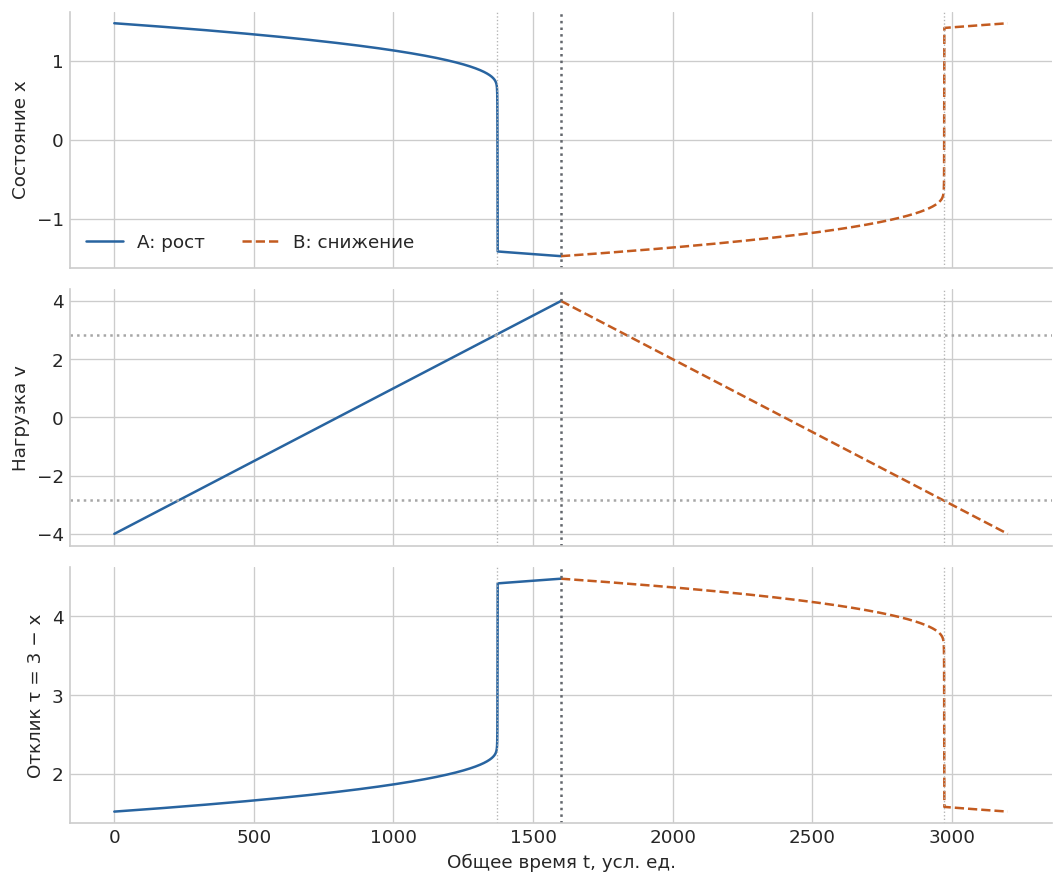

In [8]:
global_t = np.concatenate([sample_t, duration + sample_t[1:]])
all_v = np.concatenate([v_forward, v_reverse[1:]])
all_x = np.concatenate([x_forward, x_reverse[1:]])
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
for ax, data, label in zip(axes, [all_x, all_v, TAU_OFFSET-all_x],
                           ["Состояние x", "Нагрузка v", "Отклик τ = 3 − x"]):
    ax.plot(global_t[global_t <= duration], data[global_t <= duration], color=BLUE, label="A: рост")
    ax.plot(global_t[global_t >= duration], data[global_t >= duration], "--", color=ORANGE, label="B: снижение")
    ax.axvline(duration, color=GRAY, linestyle=":")
    for event in [cycle["t_forward"], cycle["t_reverse"]]:
        ax.axvline(event, color="0.7", linestyle=":", linewidth=0.8)
    ax.set_ylabel(label)
axes[0].legend(loc="lower left", ncol=2)
axes[1].axhline(V_CRIT, color="0.65", linestyle=":")
axes[1].axhline(-V_CRIT, color="0.65", linestyle=":")
axes[-1].set_xlabel("Общее время t, усл. ед.")
fig.tight_layout()
plt.show()

После разворота нагрузки при t=1600 система сохраняет высокий показатель отклика τ. Восстановление происходит лишь при пересечении обратного порога. Вертикальные пунктиры показывают разворот и события x=0; все панели используют общую ось времени.

### 3.4. Память при остановленной нагрузке

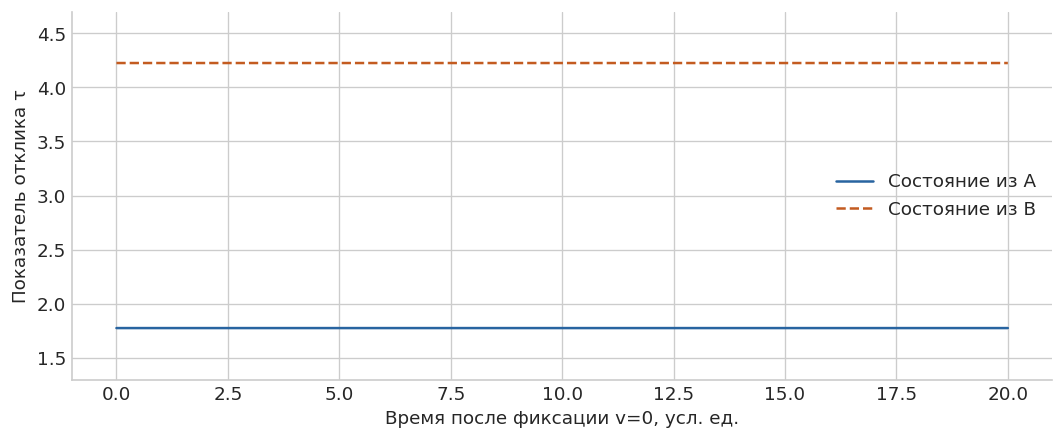

Разность после выдержки 20 ед. времени: 2.449490


In [9]:
hold_t = np.linspace(0, 20, 401)
hold_solutions = []
for initial in [x_zero_forward, x_zero_reverse]:
    sol = solve_ivp(lambda t, state: [-gradient(state[0], U, 0.0)],
                    (0, 20), [initial], t_eval=hold_t,
                    method="DOP853", rtol=RTOL, atol=ATOL, max_step=MAX_STEP)
    if not sol.success:
        raise RuntimeError(sol.message)
    hold_solutions.append(sol.y[0])
fig, ax = plt.subplots(figsize=(9, 3.8))
for values, color, style, label in zip(
    hold_solutions, [BLUE, ORANGE], ["-", "--"],
    ["Состояние из A", "Состояние из B"]
):
    ax.plot(hold_t, TAU_OFFSET-values, style, color=color, label=label)
ax.set(xlabel="Время после фиксации v=0, усл. ед.", ylabel="Показатель отклика τ",
       ylim=(1.3, 4.7))
ax.legend()
fig.tight_layout()
plt.show()
hold_gap = float(abs(hold_solutions[0][-1]-hold_solutions[1][-1]))
print(f"Разность после выдержки 20 ед. времени: {hold_gap:.6f}")

Различие сохраняется после фиксации $v=0$ и затухания переходных процессов.
Это отличает статическую бистабильность от одного лишь запаздывания.
Оба состояния притягиваются к разным минимумам $x=\pm\sqrt{3/2}$.

## 4. Верификация расчёта
### 4.1. Зависимость от скорости нагрузки

Повторим полный цикл для пяти скоростей. При замедлении динамический порог
должен приближаться к складке, а статическая область бистабильности остаётся.
Уменьшение задержки со скоростью не означает исчезновения статического гистерезиса.

,Скорость r,Время прохода,v A (x=0),v B (x=0),Задержка относительно складки,Динамическая ширина
0,0.0400,200.0,2.959075,-2.959075,0.130648,5.918150
1,0.0200,400.0,2.911439,-2.911439,0.083012,5.822878
2,0.0100,800.0,2.881043,-2.881043,0.052616,5.762087
3,0.0050,1600.0,2.861717,-2.861717,0.033290,5.723435
4,0.0025,3200.0,2.849462,-2.849462,0.021035,5.698924


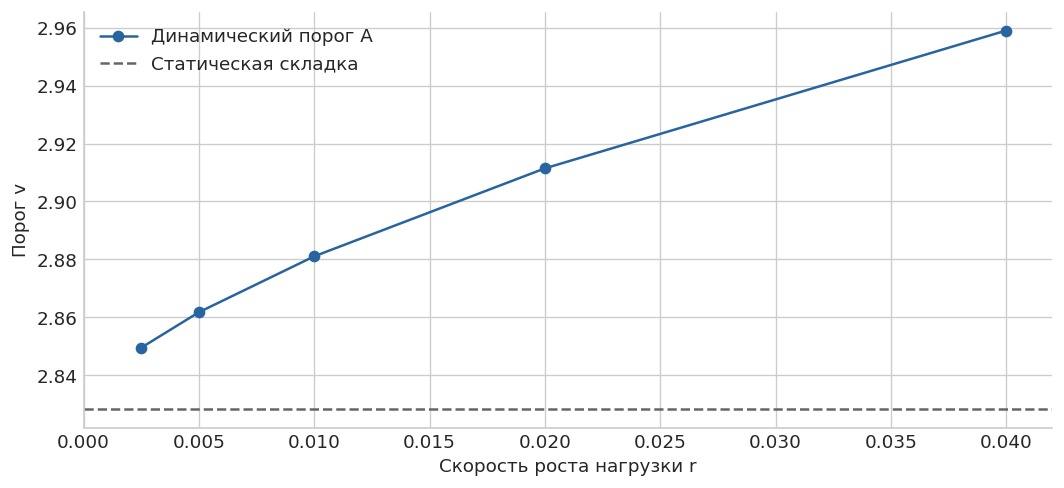

In [10]:
rate_rows = []
for rate in [0.04, 0.02, 0.01, 0.005, 0.0025]:
    result = cycle if rate == RATE else simulate_cycle(rate=rate)
    rate_rows.append([rate, result["duration"], result["v_forward"],
                      result["v_reverse"], result["v_forward"]-V_CRIT,
                      result["v_forward"]-result["v_reverse"]])
rate_table = pd.DataFrame(rate_rows, columns=[
    "Скорость r", "Время прохода", "v A (x=0)", "v B (x=0)",
    "Задержка относительно складки", "Динамическая ширина"])
display(rate_table.round(6))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(rate_table["Скорость r"], rate_table["v A (x=0)"], "o-", color=BLUE,
        label="Динамический порог A")
ax.axhline(V_CRIT, color=GRAY, linestyle="--", label="Статическая складка")
ax.set(xlabel="Скорость роста нагрузки r", ylabel="Порог v", xlim=(0, 0.042))
ax.legend()
fig.tight_layout()
plt.show()

### 4.2. Точность интегрирования и контрольные случаи

In [11]:
refined = simulate_cycle(rtol=1e-10, atol=1e-12, max_step=0.25)
threshold_difference = max(abs(cycle[key]-refined[key])
                           for key in ["v_forward", "v_reverse"])
trajectory_difference = max(
    np.max(np.abs(sol_forward.sol(sample_t)-refined["forward"].sol(sample_t))),
    np.max(np.abs(sol_reverse.sol(sample_t)-refined["reverse"].sol(sample_t))),
)

# Для неизменных параметров потенциал должен убывать.
energy_sol = solve_ivp(lambda t, state: [-gradient(state[0], U, 0.0)],
                       (0, 10), [0.2], t_eval=np.linspace(0, 10, 2001),
                       method="DOP853", rtol=1e-10, atol=1e-12, max_step=0.1)
assert energy_sol.success
energies = potential(energy_sol.y[0], U, 0.0)
max_energy_increase = float(np.max(np.diff(energies)))

# У буквального потенциала +v градиент не зависит от v.
def literal_gradient_fd(x, u, v, h=1e-5):
    def literal_potential(z):
        return z**4-u*z**2+v
    return (literal_potential(x+h)-literal_potential(x-h))/(2*h)

fold_residual = max(abs(gradient(X_FOLD, U, V_CRIT)),
                    abs(12*X_FOLD**2-2*U))
checks = {
    "Равновесия при v=0 удовлетворяют уравнению":
        np.max(np.abs(gradient(equilibria(U, 0), U, 0))) < 1e-12,
    "На складке V'=0 и V''=0": fold_residual < 1e-12,
    "Два минимума и один максимум при v=0":
        sum(12*equilibria(U, 0)**2-2*U > 0) == 2,
    "Вне сборки при v=±4 один корень":
        len(equilibria(U, V_MIN)) == len(equilibria(U, V_MAX)) == 1,
    "При u=-1 одно равновесие на всём диапазоне":
        all(len(equilibria(-1, v)) == 1 for v in np.linspace(-4, 4, 41)),
    "Конечное состояние A передано в B":
        sol_reverse.y[0, 0] == sol_forward.y[0, -1],
    "Порог A выше +vкр, порог B ниже -vкр":
        cycle["v_forward"] > V_CRIT and cycle["v_reverse"] < -V_CRIT,
    "При v=0 состояния различаются": zero_gap > 2.4,
    "После выдержки память сохраняется": abs(hold_gap-2*np.sqrt(U/2)) < 1e-7,
    "При замедлении пороги приближаются к складкам":
        np.all(np.diff(rate_table["Задержка относительно складки"]) < 0),
    "Уточнение: различие порогов < 1e-5": threshold_difference < 1e-5,
    "Уточнение: различие траекторий < 1e-4": trajectory_difference < 1e-4,
    "При постоянной нагрузке V не возрастает": max_energy_increase < 1e-9,
    "Буквальное +v не меняет градиент":
        abs(literal_gradient_fd(0.4, U, -4)-literal_gradient_fd(0.4, U, 4)) < 1e-9,
    "Условные нагрузка и отклик положительны":
        np.min(LOAD_OFFSET+all_v) > 0 and np.min(TAU_OFFSET-all_x) > 0,
}
display(pd.DataFrame({"Проверка": list(checks),
                      "Результат": ["Пройдена" if v else "ОШИБКА" for v in checks.values()]}))
print(f"Различие порогов: {threshold_difference:.3e}")
print(f"Максимальное различие траекторий: {trajectory_difference:.3e}")
print(f"Максимальный прирост V при фиксированном v: {max_energy_increase:.3e}")
assert all(checks.values()), "Есть непройденные проверки"

,Проверка,Результат
0,Равновесия при v=0 удовлетворяют уравнению,Пройдена
1,На складке V'=0 и V''=0,Пройдена
2,Два минимума и один максимум при v=0,Пройдена
3,Вне сборки при v=±4 один корень,Пройдена
4,При u=-1 одно равновесие на всём диапазоне,Пройдена
5,Конечное состояние A передано в B,Пройдена
6,"Порог A выше +vкр, порог B ниже -vкр",Пройдена
7,При v=0 состояния различаются,Пройдена
8,После выдержки память сохраняется,Пройдена
9,При замедлении пороги приближаются к складкам,Пройдена


Различие порогов: 2.519e-11
Максимальное различие траекторий: 5.983e-07
Максимальный прирост V при фиксированном v: 1.776e-15


## 5. Ответы на вопросы

**1. Почему отклик не восстанавливается сразу после снижения нагрузки?**

После прямого скачка система попадает в другую потенциальную яму. При снижении
нагрузки эта яма ещё существует и остаётся устойчивой. Чтобы самопроизвольно
вернуться на ветвь малого отклика в детерминированной модели, нужно достичь
обратной складки; малое снижение нагрузки этого не обеспечивает.

**2. Как это объясняет сбой при нагрузке ниже пиковой?**

История нагрузки влияет на состояние. После перегрузки сервис может оставаться
в режиме большого отклика при уже меньшем трафике, хотя до перегрузки тот же
трафик обслуживался нормально. Возможная IT-интерпретация — накопленная очередь
или повторные запросы, поддерживающие перегруженное состояние. Это аналогия:
очередь, тайм-ауты и повторы в уравнении отдельно не моделируются.

**3. Какие рекомендации следуют для мониторинга и проектирования?**

- Выполнять нагрузочные испытания и на росте, и на спаде трафика; фиксировать
  отдельно пороги деградации и восстановления.
- Следить за задержками, длиной очередей, ошибками, повторными запросами и
  насыщением ресурсов вместе с текущей интенсивностью запросов.
- Сохранять запас до выявленного порога деградации; при восстановлении
  разгружать сервис достаточно сильно и выдерживать время на опустошение очередей.
- Использовать ограничение входного потока, ограниченные очереди и бюджеты
  повторов; экспериментально проверять, помогают ли они выйти из плохого режима.
- Проверять политику масштабирования по данным конкретной системы. Значение
  $u$ в нормальной форме само по себе не задаёт необходимое число инстансов.

## 6. Заключение

Построено бифуркационное множество $8u^3=27v^2$ и выполнены согласованные
прямой и обратный эксперименты для градиентной модели сборки.
При $u=3$ статические пороги равны $\pm2{,}828427$.
Сохранение разных состояний при $v=0$ после выдержки подтверждает бистабильность,
а разные пороги при росте и снижении нагрузки — гистерезис.

Конечная скорость изменения нагрузки даёт дополнительную динамическую задержку;
её отличие от статической ширины петли проверено изменением скорости.
Точные динамические значения и показатели точности приведены в выполненных ячейках.
Интерпретация в терминах веб-сервиса качественная: для количественного прогноза
требуется связь коэффициентов модели с измерениями реальной системы.

In [12]:
# Числовые результаты для сопоставления с PDF-отчётом.
report_data = {
    "u": U, "rate": RATE, "duration": duration, "v_critical": V_CRIT,
    "x_fold": X_FOLD, "v_forward": cycle["v_forward"],
    "v_reverse": cycle["v_reverse"], "t_forward": cycle["t_forward"],
    "t_reverse": cycle["t_reverse"], "dynamic_width": dynamic_width,
    "x_zero_forward": x_zero_forward, "x_zero_reverse": x_zero_reverse,
    "zero_gap": zero_gap, "hold_gap": hold_gap,
    "threshold_difference": threshold_difference,
    "trajectory_difference": float(trajectory_difference),
    "max_energy_increase": max_energy_increase,
    "checks": {k: bool(v) for k, v in checks.items()},
    "rate_rows": rate_table.to_dict(orient="records"),
    "initial_x": float(x_forward[0]), "final_x": float(x_reverse[-1]),
}
print(f"Итог: {sum(checks.values())}/{len(checks)} проверок пройдено.")

Итог: 15/15 проверок пройдено.
